# 03.04 — Exploración inicial de NYC Taxi y NOAA (2024)

**Proyecto de Big Data · Fase 03: Ingesta y exploración**

## Propósito

Explorar los patrones de movilidad de **NYC Yellow Taxi durante 2024** e integrar, a escala diaria, las observaciones meteorológicas de **NOAA / Central Park**. A diferencia de `03_03_data_profiling`, que documentó problemas de calidad, este notebook se concentra en **demanda temporal, características de los viajes, concentración espacial y asociaciones descriptivas con el clima**.

**Preguntas guía**

1. ¿Cómo cambia la demanda de viajes por mes, día de la semana y hora?
2. ¿Qué describen los cuantiles sobre distancia, duración e importe, frente a sus valores extremos?
3. ¿Qué zonas concentran los registros de origen y destino?
4. ¿Qué relaciones descriptivas aparecen al cruzar viajes diarios con variables meteorológicas?

## 1. Entorno y fuentes

### 1.1. Bibliotecas y sesión Spark

Se utiliza Spark para leer y agregar los archivos Parquet de Taxi. `pandas` y `matplotlib` se emplean para tablas pequeñas y gráficas. **No se utiliza `cache()` sobre los ~41 millones de registros**, evitando la presión de memoria observada en el notebook anterior.

In [85]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

In [86]:
spark = (
    SparkSession.builder
    .appName("03_04_initial_exploration")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

In [87]:
print("=" * 60)
print("INFORMACIÓN DEL ENTORNO SPARK")
print("=" * 60)

print(f"Spark version: {spark.version}")
print(f"Application name: {spark.sparkContext.appName}")
print(f"Master: {spark.sparkContext.master}")
print(f"Default parallelism: {spark.sparkContext.defaultParallelism}")

INFORMACIÓN DEL ENTORNO SPARK
Spark version: 4.1.3
Application name: 03_04_initial_exploration
Master: local[*]
Default parallelism: 12


### 1.2. Rutas y carga de la capa `raw`

Las fuentes mantienen sus formatos originales: **Parquet mensual para Taxi** y **JSON paginado de la API NOAA**. No se escriben archivos ni se altera `data/raw/`. Se conserva la distinción entre almacenamiento original y vistas analíticas temporales.

In [88]:
YEAR = 2024

PROJECT_ROOT = Path.cwd().parent

TAXI_RAW_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "taxi"
    / f"year={YEAR}"
)

WEATHER_RAW_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "weather"
    / f"year={YEAR}"
    / "station=USW00094728"
)

In [89]:
taxi_df = (
    spark.read
    .parquet(str(TAXI_RAW_DIR))
)

In [90]:
weather_raw_df = (
    spark.read
    .option("multiLine", True)
    .json(str(WEATHER_RAW_DIR))
)

weather_df = (
    weather_raw_df
    .select(
        F.explode("results").alias("record")
    )
    .select("record.*")
    .withColumn(
        "observation_date",
        F.to_date("date")
    )
)

### 1.3. Alcance analítico y variables derivadas

Para representar la demanda en 2024 se usan únicamente *pickups* entre `2024-01-01` (incluido) y `2025-01-01` (excluido). En `03_03` se detectaron 56 pickups fuera de ese intervalo; se omiten **solo de esta vista analítica**, sin eliminarlos de la fuente.

La unidad de observación del dataset principal sigue siendo **un viaje**. Las columnas derivadas (fecha, mes, hora, día de la semana y duración) permiten agregaciones posteriores. Se mantiene la duración tal como se deriva de las marcas temporales: no se aplica aquí un criterio definitivo de limpieza.

In [91]:
taxi_2024_df = (
    taxi_df
    .filter(
        (F.col("tpep_pickup_datetime") >= "2024-01-01")
        &
        (F.col("tpep_pickup_datetime") < "2025-01-01")
    )
    .withColumn(
        "pickup_date",
        F.to_date("tpep_pickup_datetime")
    )
    .withColumn(
        "pickup_month",
        F.month("tpep_pickup_datetime")
    )
    .withColumn(
        "pickup_hour",
        F.hour("tpep_pickup_datetime")
    )
    .withColumn(
        "day_of_week",
        F.dayofweek("tpep_pickup_datetime")
    )
    .withColumn(
        "duration_minutes",
        (
            F.unix_timestamp("tpep_dropoff_datetime")
            - F.unix_timestamp("tpep_pickup_datetime")
        ) / 60
    )
)

## 2. Patrones temporales de demanda

La **demanda observada** se aproxima mediante el número de registros de pickup. Es una medida del volumen registrado de Yellow Taxi, **no de todas las solicitudes de transporte de la ciudad**. Primero se examinan ciclos anuales y diarios; después se estudia la estacionalidad semanal y horaria.

### 2.1. Demanda mensual

La agrupación mensual proporciona una primera aproximación a la estacionalidad anual. Los totales, sin embargo, dependen parcialmente de cuántos días tiene cada mes.

In [92]:
monthly_demand_df = (
    taxi_2024_df
    .groupBy("pickup_month")
    .agg(
        F.count("*").alias("trips")
    )
    .orderBy("pickup_month")
)

monthly_demand_df.show(12)

+------------+-------+
|pickup_month|  trips|
+------------+-------+
|           1|2964617|
|           2|3007533|
|           3|3582611|
|           4|3514295|
|           5|3723843|
|           6|3539170|
|           7|3076876|
|           8|2979192|
|           9|3633025|
|          10|3833780|
|          11|3646372|
|          12|3668350|
+------------+-------+



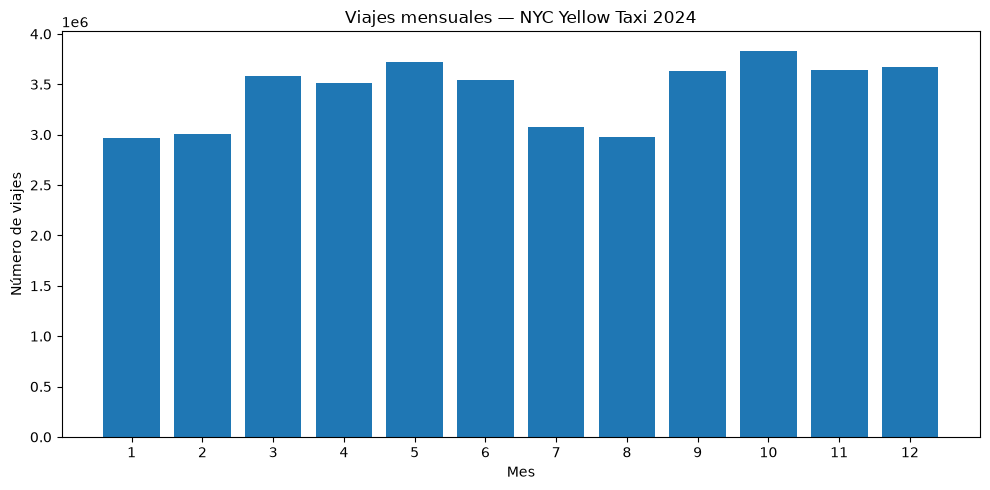

In [93]:
monthly_pd = monthly_demand_df.toPandas()

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_pd["pickup_month"],
    monthly_pd["trips"]
)

plt.title("Viajes mensuales — NYC Yellow Taxi 2024")
plt.xlabel("Mes")
plt.ylabel("Número de viajes")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

**Lectura de los resultados.** Octubre presenta el mayor volumen (**3,833,780 viajes**), mientras que enero (**2,964,617**) y agosto (**2,979,192**) están entre los meses de menor actividad. También se observa una recuperación desde septiembre hasta octubre. Estos cambios describen el volumen observado y **no identifican por sí solos su causa**.

**Precaución:** comparar febrero con meses de 30 o 31 días usando solamente totales puede exagerar las diferencias. Para complementar el resultado, conviene utilizar una tasa diaria media.

#### Análisis adicional — demanda media por día de cada mes

Para evitar que la longitud de cada mes distorsione la comparación, dividimos el total de viajes entre sus días calendario (incluidos los 29 días de febrero de 2024). Esta es una **media diaria mensual**, no una media por vehículo o por zona. La operación se realiza en pandas sobre 12 filas ya agregadas.

 pickup_month   trips  days_in_month trips_per_day
            1 2964617             31        95,633
            2 3007533             29       103,708
            3 3582611             31       115,568
            4 3514295             30       117,143
            5 3723843             31       120,124
            6 3539170             30       117,972
            7 3076876             31        99,254
            8 2979192             31        96,103
            9 3633025             30       121,101
           10 3833780             31       123,670
           11 3646372             30       121,546
           12 3668350             31       118,334


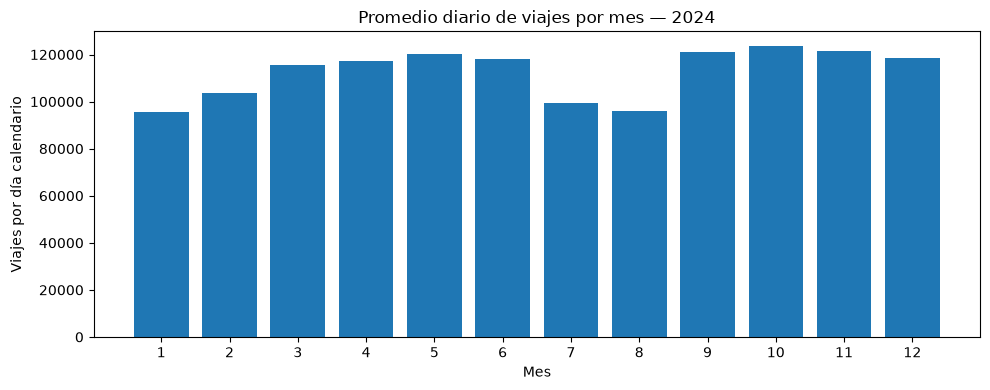

In [94]:
monthly_daily_pd = monthly_pd.copy()
monthly_daily_pd["days_in_month"] = monthly_daily_pd["pickup_month"].apply(
    lambda month: pd.Period(f"{YEAR}-{int(month):02d}").days_in_month
)
monthly_daily_pd["trips_per_day"] = (
    monthly_daily_pd["trips"] / monthly_daily_pd["days_in_month"]
)

print(monthly_daily_pd.to_string(index=False, formatters={
    "trips_per_day": "{:,.0f}".format
}))

plt.figure(figsize=(10, 4))
plt.bar(monthly_daily_pd["pickup_month"], monthly_daily_pd["trips_per_day"])
plt.title("Promedio diario de viajes por mes — 2024")
plt.xlabel("Mes")
plt.ylabel("Viajes por día calendario")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

**Interpretación — promedio diario por mes.** La normalización confirma que **octubre mantiene el primer lugar**, con **123,670 viajes por día**, seguido de niveles similares en noviembre (**121,546**) y septiembre (**121,101**). En contraste, enero registra **95,633 diarios** y agosto **96,103**; julio también presenta un nivel bajo (**99,254**).

La diferencia octubre–enero es de aproximadamente **29.3 %**, por lo que la variación mensual **no se explica únicamente por tener meses de distinta duración**. Se observa una caída en julio-agosto y una recuperación a partir de septiembre. Estos patrones motivan incluir el mes o una componente estacional en análisis posteriores, sin atribuir aún sus causas.

### 2.2. Evolución diaria

La serie temporal diaria permite observar fluctuaciones entre días que quedan ocultas en los promedios mensuales.

In [95]:
daily_demand_df = (
    taxi_2024_df
    .groupBy("pickup_date")
    .agg(
        F.count("*").alias("trips")
    )
    .orderBy("pickup_date")
)

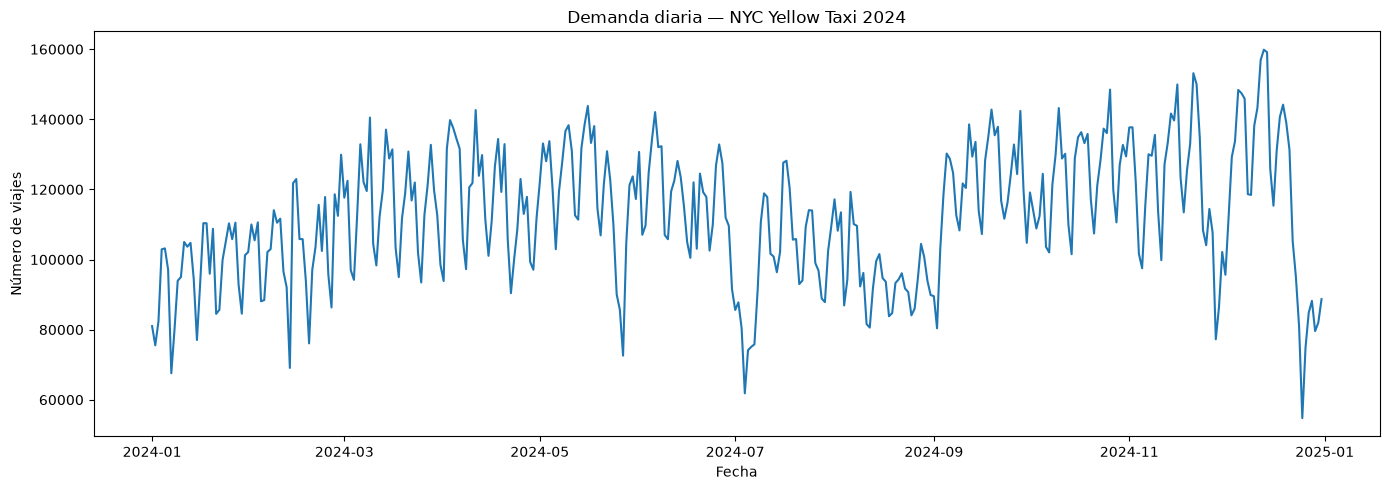

In [96]:
daily_pd = daily_demand_df.toPandas()

plt.figure(figsize=(14, 5))

plt.plot(
    daily_pd["pickup_date"],
    daily_pd["trips"]
)

plt.title("Demanda diaria — NYC Yellow Taxi 2024")
plt.xlabel("Fecha")
plt.ylabel("Número de viajes")

plt.tight_layout()
plt.show()

**Lectura de la gráfica.** La demanda diaria exhibe una marcada **oscilación recurrente** y episodios de caídas pronunciadas, especialmente visibles a mitad y al final del año. La gráfica no permite atribuir esas caídas exclusivamente al clima, las vacaciones u otros eventos; esas explicaciones requieren controles o información adicional.

#### Análisis adicional — tendencia suavizada y días extremos

La **media móvil centrada de siete días** ayuda a visualizar la trayectoria a lo largo del año, reduciendo las oscilaciones semanales. Se complementa con las cinco fechas de mayor y menor volumen.

La media móvil centrada incorpora días anteriores y posteriores a cada fecha: es válida para descripción retrospectiva, **no debe emplearse directamente como predictor** en una evaluación temporal futura. Las fechas extremas representan demanda inusual, no necesariamente errores de registro.

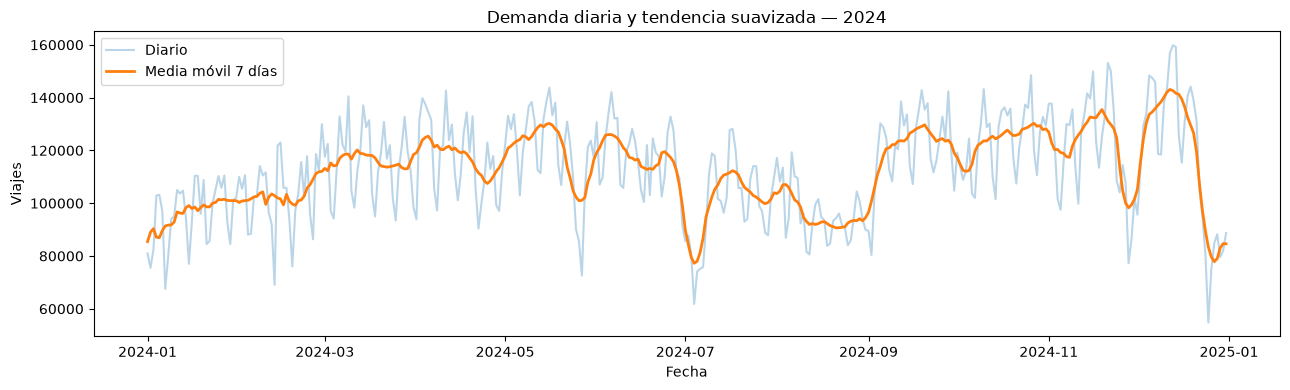

Cinco fechas con menor número de viajes
pickup_date  trips
 2024-12-25  54764
 2024-07-04  61817
 2024-01-07  67543
 2024-02-13  69067
 2024-05-27  72579

Cinco fechas con mayor número de viajes
pickup_date  trips
 2024-12-13 159845
 2024-12-14 159150
 2024-12-12 156911
 2024-11-21 153149
 2024-11-22 150016


In [97]:
daily_analysis_pd = daily_pd.copy()
daily_analysis_pd["pickup_date"] = pd.to_datetime(daily_analysis_pd["pickup_date"])
daily_analysis_pd = daily_analysis_pd.sort_values("pickup_date").reset_index(drop=True)
daily_analysis_pd["rolling_7d"] = (
    daily_analysis_pd["trips"].rolling(window=7, center=True, min_periods=4).mean()
)

plt.figure(figsize=(13, 4))
plt.plot(daily_analysis_pd["pickup_date"], daily_analysis_pd["trips"],
         alpha=0.30, label="Diario")
plt.plot(daily_analysis_pd["pickup_date"], daily_analysis_pd["rolling_7d"],
         linewidth=2, label="Media móvil 7 días")
plt.title("Demanda diaria y tendencia suavizada — 2024")
plt.xlabel("Fecha")
plt.ylabel("Viajes")
plt.legend()
plt.tight_layout()
plt.show()

print("Cinco fechas con menor número de viajes")
print(daily_analysis_pd.nsmallest(5, "trips")[["pickup_date", "trips"]].to_string(index=False))
print("\nCinco fechas con mayor número de viajes")
print(daily_analysis_pd.nlargest(5, "trips")[["pickup_date", "trips"]].to_string(index=False))

**Interpretación — serie suavizada y días extremos.** La media móvil describe incrementos generales durante la primavera, una reducción en parte del verano y una recuperación en otoño, con oscilaciones persistentes dentro de cada periodo.

Los **cinco días de menor volumen** fueron el **25 de diciembre (54,764)**, **4 de julio (61,817)**, **7 de enero (67,543)**, **13 de febrero (69,067)** y **27 de mayo (72,579)**. Los **cinco mayores** se concentran en noviembre y diciembre: **13 de diciembre (159,845)**, **14 de diciembre (159,150)**, **12 de diciembre (156,911)**, **21 de noviembre (153,149)** y **22 de noviembre (150,016)**.

Algunas fechas bajas corresponden a **festivos conocidos** (25 de diciembre y 4 de julio), pero la coincidencia no permite cuantificar su efecto ni explicar por sí sola el resto de los extremos. La concentración de tres días elevados consecutivos en diciembre sugiere estudiar calendario y eventos en una fase analítica posterior.

### 2.3. Diferencias por día de la semana

Spark numera los días de la semana del **1 (domingo) al 7 (sábado)**. El gráfico original presenta el número **acumulado anual** de viajes registrados en cada día.

In [98]:
DAY_NAMES = F.create_map(
    F.lit(1), F.lit("Domingo"),
    F.lit(2), F.lit("Lunes"),
    F.lit(3), F.lit("Martes"),
    F.lit(4), F.lit("Miércoles"),
    F.lit(5), F.lit("Jueves"),
    F.lit(6), F.lit("Viernes"),
    F.lit(7), F.lit("Sábado")
)

In [99]:
weekday_demand_df = (
    taxi_2024_df
    .groupBy("day_of_week")
    .agg(
        F.count("*").alias("trips")
    )
    .withColumn(
        "day_name",
        DAY_NAMES[F.col("day_of_week")]
    )
    .orderBy("day_of_week")
)

weekday_demand_df.show()

+-----------+-------+---------+
|day_of_week|  trips| day_name|
+-----------+-------+---------+
|          1|5273142|  Domingo|
|          2|5113701|    Lunes|
|          3|5901464|   Martes|
|          4|6117764|Miércoles|
|          5|6428160|   Jueves|
|          6|6103900|  Viernes|
|          7|6231533|   Sábado|
+-----------+-------+---------+



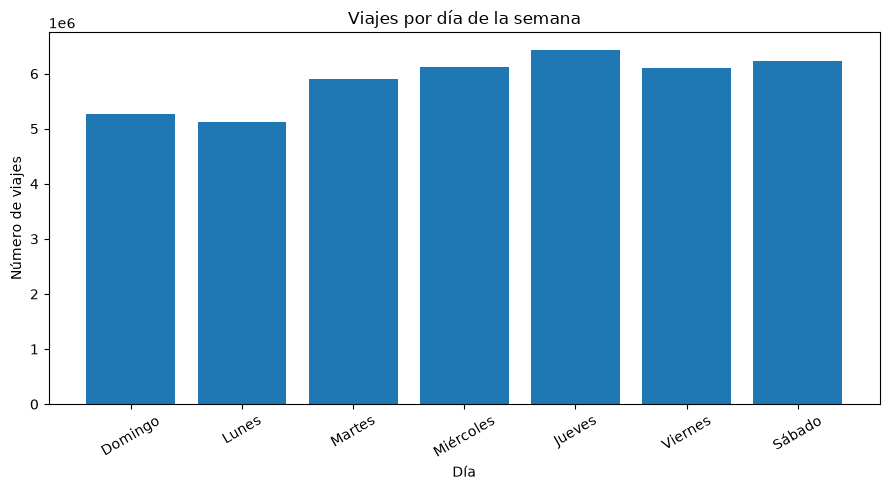

In [100]:
weekday_pd = weekday_demand_df.toPandas()

plt.figure(figsize=(9, 5))

plt.bar(
    weekday_pd["day_name"],
    weekday_pd["trips"]
)

plt.title("Viajes por día de la semana")
plt.xlabel("Día")
plt.ylabel("Número de viajes")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Lectura de los resultados.** En acumulados, **jueves (6,428,160)** y **sábado (6,231,533)** son de los días más activos; **lunes (5,113,701)** es el menor. No obstante, 2024 tuvo **53 lunes y 53 martes**, y 52 ocurrencias de los demás días: por ello, el total acumulado no equivale exactamente a un *día típico*.

#### Análisis adicional — demanda media por ocurrencia del día de semana

Se calcula el promedio de viajes de un lunes, martes, etc., a partir de la **serie diaria agregada**. Esta normalización corrige la diferencia en el número de apariciones de cada día: en 2024 hubo 53 lunes y martes y 52 ocurrencias de los demás días. No se requiere volver a leer los archivos Parquet.

weekday_name  calendar_days  mean_daily_trips
       Lunes             53      96484.924528
      Martes             53     111348.377358
   Miércoles             52     117649.307692
      Jueves             52     123618.461538
     Viernes             52     117382.692308
      Sábado             52     119837.173077
     Domingo             52     101406.576923


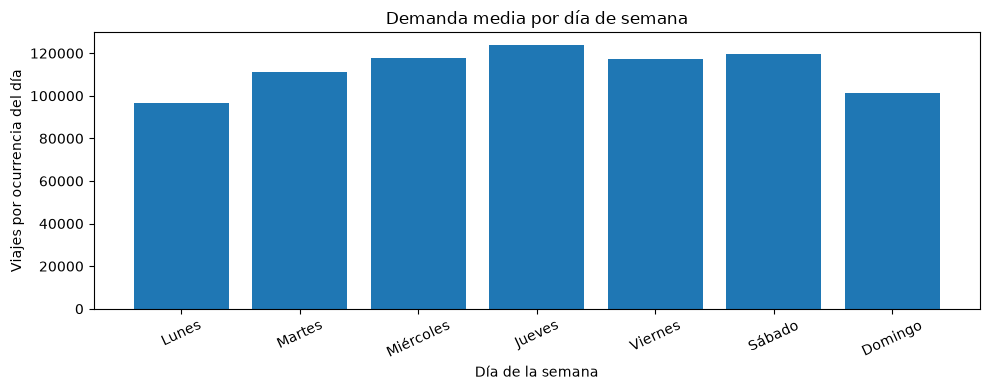

In [101]:
weekday_labels = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
weekday_average_pd = daily_analysis_pd.copy()
weekday_average_pd["weekday_name"] = pd.Categorical(
    weekday_average_pd["pickup_date"].dt.day_name().map({
        "Monday": "Lunes", "Tuesday": "Martes", "Wednesday": "Miércoles",
        "Thursday": "Jueves", "Friday": "Viernes", "Saturday": "Sábado",
        "Sunday": "Domingo"
    }),
    categories=weekday_labels,
    ordered=True
)
weekday_average_pd = (
    weekday_average_pd.groupby("weekday_name", observed=True)
    .agg(calendar_days=("trips", "size"), mean_daily_trips=("trips", "mean"))
    .reset_index()
)
print(weekday_average_pd.to_string(index=False))

plt.figure(figsize=(10, 4))
plt.bar(weekday_average_pd["weekday_name"].astype(str),
        weekday_average_pd["mean_daily_trips"])
plt.title("Demanda media por día de semana")
plt.xlabel("Día de la semana")
plt.ylabel("Viajes por ocurrencia del día")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**Interpretación — comparación semanal normalizada.** El **jueves** conserva la mayor demanda diaria media (**123,618 viajes**), mientras que el **lunes** registra la menor (**96,485**). La diferencia es de aproximadamente **27,134 viajes por día, o 28.1 %** respecto al lunes. El sábado se mantiene elevado (**119,837**) y el domingo es relativamente bajo (**101,407**).

Esta comparación es más apropiada que los acumulados semanales para caracterizar un *día típico* de cada categoría. El patrón confirma que el **día de semana es una variable explicativa potencial** para estudios posteriores de demanda, aunque todavía no controla eventos específicos o condiciones meteorológicas.

### 2.4. Distribución horaria

Se agregan viajes por hora del pickup, independientemente de la fecha. La gráfica representa los totales de 2024 para cada hora del reloj.

In [102]:
hourly_demand_df = (
    taxi_2024_df
    .groupBy("pickup_hour")
    .agg(
        F.count("*").alias("trips")
    )
    .orderBy("pickup_hour")
)

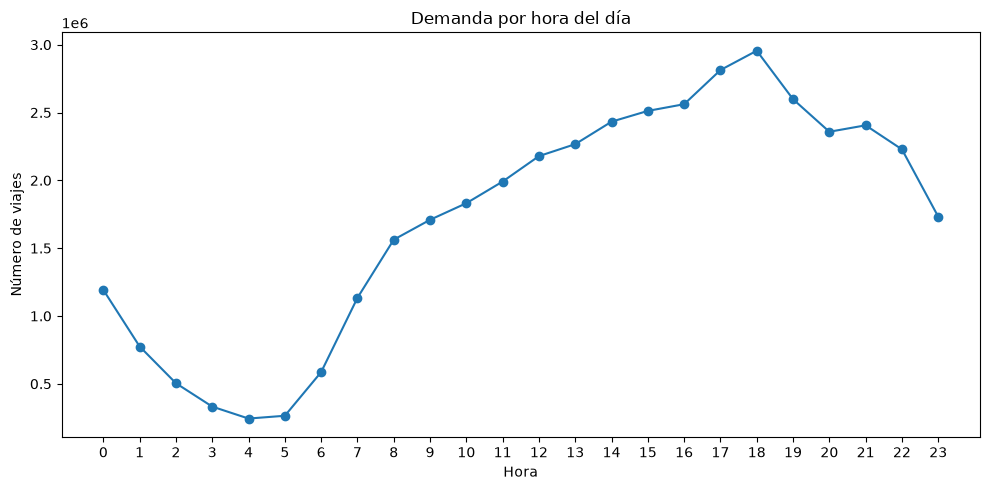

In [103]:
hourly_pd = hourly_demand_df.toPandas()

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_pd["pickup_hour"],
    hourly_pd["trips"],
    marker="o"
)

plt.title("Demanda por hora del día")
plt.xlabel("Hora")
plt.ylabel("Número de viajes")

plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

**Lectura de la gráfica.** El mínimo se concentra alrededor de las **04:00–05:00**, seguido por un aumento marcado desde la mañana. La mayor actividad ocurre alrededor de las **18:00**, y comienza a reducirse después. Es un patrón descriptivo del servicio Yellow Taxi, no una medida directa de congestión vial.

### 2.5. Interacción entre día y hora

La matriz de calor conserva simultáneamente los ciclos semanales y diarios y permite localizar franjas con intensidad alta o baja. Su escala muestra **conteos acumulados**, por lo que su interpretación también depende de cuántas veces ocurre cada día de semana.

In [104]:
weekday_hour_df = (
    taxi_2024_df
    .groupBy(
        "day_of_week",
        "pickup_hour"
    )
    .agg(
        F.count("*").alias("trips")
    )
)

In [105]:
weekday_hour_pd = (
    weekday_hour_df
    .toPandas()
    .pivot(
        index="day_of_week",
        columns="pickup_hour",
        values="trips"
    )
    .sort_index()
)

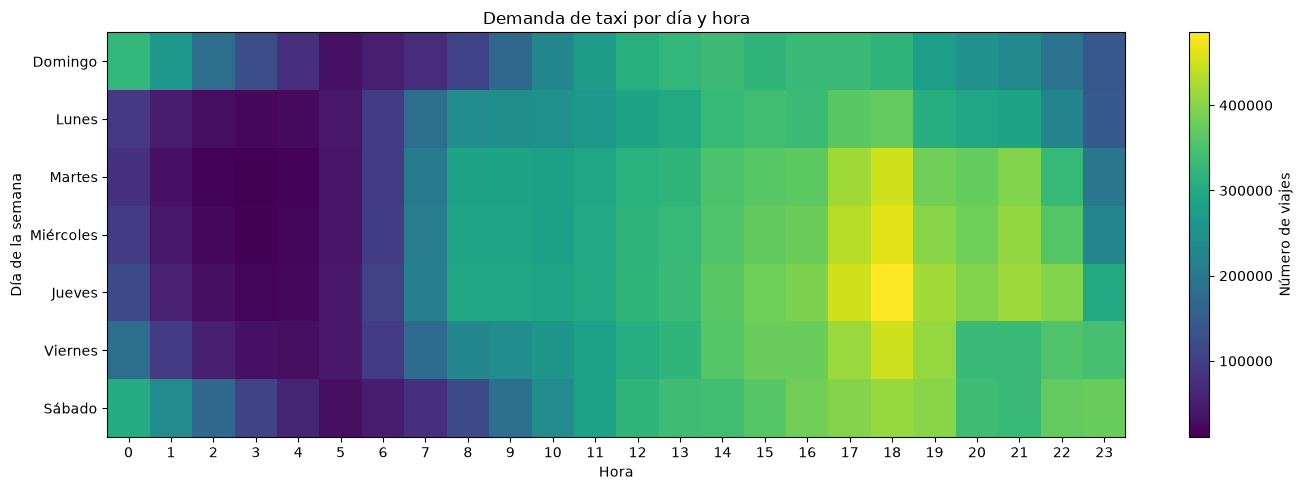

In [106]:
plt.figure(figsize=(14, 5))

plt.imshow(
    weekday_hour_pd.values,
    aspect="auto"
)

plt.colorbar(
    label="Número de viajes"
)

plt.yticks(
    range(7),
    [
        "Domingo",
        "Lunes",
        "Martes",
        "Miércoles",
        "Jueves",
        "Viernes",
        "Sábado"
    ]
)

plt.xticks(
    range(24),
    range(24)
)

plt.xlabel("Hora")
plt.ylabel("Día de la semana")
plt.title("Demanda de taxi por día y hora")

plt.tight_layout()
plt.show()

**Lectura de la matriz.** Se aprecian concentraciones especialmente elevadas en las **tardes de martes a jueves** y un patrón nocturno diferente durante el fin de semana. Las madrugadas de los días laborales presentan menor actividad. Estas diferencias sugieren que **hora y día deben analizarse conjuntamente** en etapas posteriores.

## 3. Características de los viajes

Durante el profiling se identificaron valores extremos en distancia, duración e importes. Por ello, este apartado separa **cuantiles robustos** de **visualizaciones truncadas con fines gráficos**.

**Criterio:** los percentiles se estiman mediante `approxQuantile` para evitar ordenaciones exactas costosas sobre el conjunto masivo. Los valores representados son aproximados y no deben confundirse con reglas automáticas de limpieza.

### 3.1. Cuantiles de distancia, duración e importe

In [107]:
EXPLORATION_COLUMNS = [
    "trip_distance",
    "duration_minutes",
    "total_amount"
]

quantiles = (
    taxi_2024_df
    .approxQuantile(
        EXPLORATION_COLUMNS,
        [0.50, 0.90, 0.95, 0.99],
        0.001
    )
)

In [108]:
for column, values in zip(
    EXPLORATION_COLUMNS,
    quantiles
):
    print(
        f"{column:<20} "
        f"P50={values[0]:.2f} "
        f"P90={values[1]:.2f} "
        f"P95={values[2]:.2f} "
        f"P99={values[3]:.2f}"
    )

trip_distance        P50=1.76 P90=8.80 P95=14.20 P99=19.95
duration_minutes     P50=13.00 P90=33.02 P95=43.98 P99=70.20
total_amount         P50=21.00 P90=56.64 P95=82.69 P99=104.88


**Resultados observados:**

| Variable | P50 | P90 | P95 | P99 |
|---|---:|---:|---:|---:|
| Distancia (`trip_distance`) | 1.76 | 8.80 | 14.20 | 19.95 |
| Duración (minutos) | 13.00 | 33.02 | 43.98 | 70.20 |
| Importe total (`total_amount`) | 21.00 | 56.64 | 82.69 | 104.88 |

Los cuantiles muestran que el viaje típico es mucho menor que varios máximos extremos identificados durante `03_03`. La fuerte separación entre mediana y cola alta justifica no describir estas variables únicamente mediante la media.

### 3.2. Muestra para histogramas

La vista para las gráficas conserva viajes con distancia e importe no negativos, duración positiva y las tres variables **por debajo de sus respectivos P99**. Después se selecciona aleatoriamente una fracción (semilla fija).

> **Importante:** el recorte se aplica **simultáneamente a las tres variables**: las distribuciones visualizadas son **condicionales a esos filtros**, no una representación de todos los viajes de 2024. Ningún dato se elimina de `raw`. Convertimos a pandas solo la muestra, nunca las 41.17 M de filas.

In [109]:
distance_p99 = quantiles[0][3]
duration_p99 = quantiles[1][3]
amount_p99 = quantiles[2][3]

In [110]:
distribution_sample_df = (
    taxi_2024_df
    .filter(
        (F.col("trip_distance") >= 0)
        &
        (F.col("trip_distance") <= distance_p99)
        &
        (F.col("duration_minutes") > 0)
        &
        (F.col("duration_minutes") <= duration_p99)
        &
        (F.col("total_amount") >= 0)
        &
        (F.col("total_amount") <= amount_p99)
    )
    .select(
        "trip_distance",
        "duration_minutes",
        "total_amount"
    )
    .sample(
        withReplacement=False,
        fraction=0.005,
        seed=42
    )
)

In [111]:
distribution_pd = distribution_sample_df.toPandas()

### 3.3. Distribuciones observadas

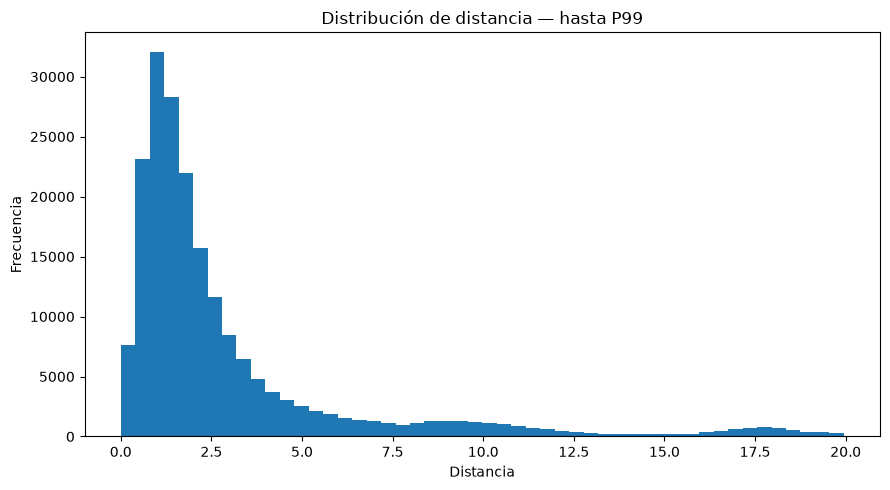

In [112]:
plt.figure(figsize=(9, 5))

plt.hist(
    distribution_pd["trip_distance"],
    bins=50
)

plt.title("Distribución de distancia — hasta P99")
plt.xlabel("Distancia")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

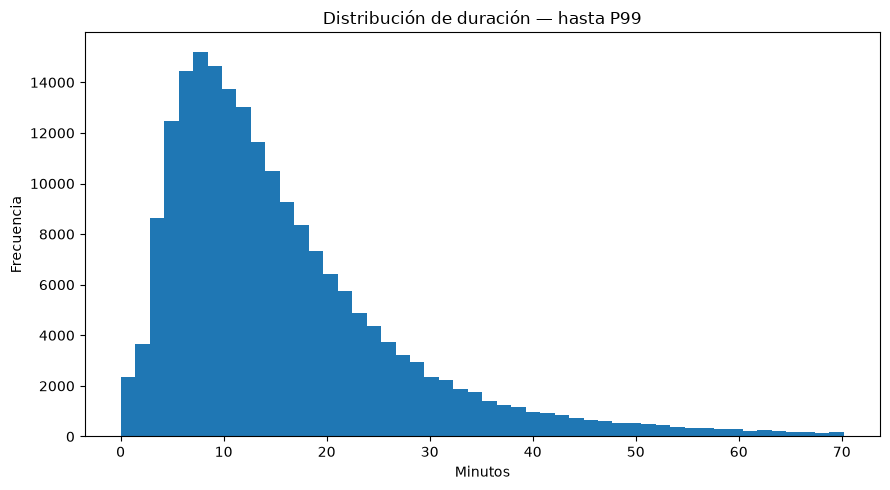

In [113]:
plt.figure(figsize=(9, 5))

plt.hist(
    distribution_pd["duration_minutes"],
    bins=50
)

plt.title("Distribución de duración — hasta P99")
plt.xlabel("Minutos")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

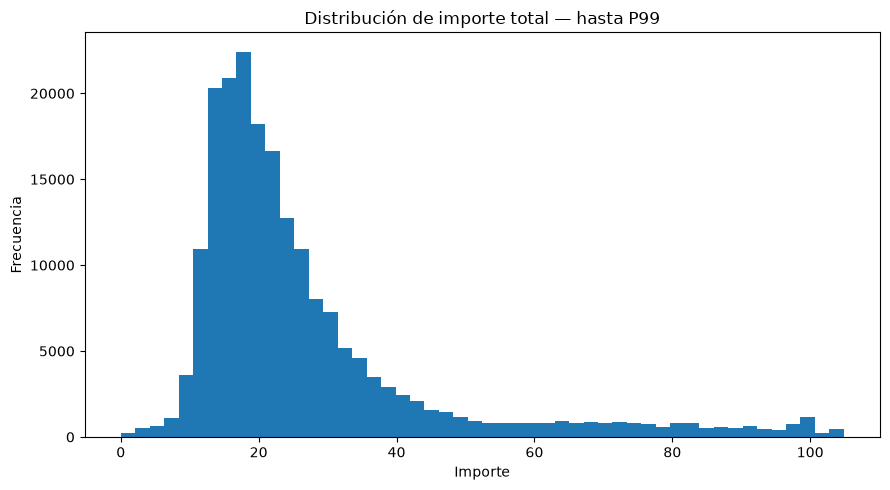

In [114]:
plt.figure(figsize=(9, 5))

plt.hist(
    distribution_pd["total_amount"],
    bins=50
)

plt.title("Distribución de importe total — hasta P99")
plt.xlabel("Importe")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

**Interpretación conjunta.** Los histogramas de distancia, duración e importe están **sesgados a la derecha**: abundan los viajes cortos o de importe moderado y aparecen colas hacia valores más altos. La distancia se concentra especialmente en valores bajos; la duración se concentra alrededor de viajes de pocos minutos a decenas de minutos. No se observan aquí los extremos más severos, porque el propósito del corte por percentiles es facilitar la lectura gráfica.

**Límites:** estos gráficos no permiten evaluar proporciones poblacionales sin tener en cuenta el muestreo y el filtrado conjunto; tampoco justifican descartar automáticamente los viajes largos o caros.

## 4. Concentración espacial de pickups y dropoffs

Los identificadores `PULocationID` y `DOLocationID` describen zonas, **no coordenadas ni nombres de barrios**. En esta fase se compara su frecuencia, dejando el enriquecimiento geográfico mediante *Taxi Zone Lookup* para el pipeline de transformación.

In [115]:
top_pickup_zones_df = (
    taxi_2024_df
    .groupBy("PULocationID")
    .agg(
        F.count("*").alias("trips")
    )
    .orderBy(
        F.desc("trips")
    )
    .limit(15)
)

top_pickup_zones_df.show()

+------------+-------+
|PULocationID|  trips|
+------------+-------+
|         132|1989986|
|         237|1915438|
|         161|1914605|
|         236|1729895|
|         162|1418846|
|         230|1391157|
|         186|1362156|
|         142|1314690|
|         138|1295499|
|         170|1176580|
|         163|1170192|
|         239|1142282|
|          68|1113865|
|         234|1105436|
|          48|1040758|
+------------+-------+



In [116]:
top_dropoff_zones_df = (
    taxi_2024_df
    .groupBy("DOLocationID")
    .agg(
        F.count("*").alias("trips")
    )
    .orderBy(
        F.desc("trips")
    )
    .limit(15)
)

top_dropoff_zones_df.show()

+------------+-------+
|DOLocationID|  trips|
+------------+-------+
|         236|1793164|
|         237|1723799|
|         161|1539903|
|         230|1310989|
|         170|1212884|
|         162|1183373|
|         142|1141647|
|         239|1131543|
|          68|1075719|
|         141|1061309|
|         163|1018857|
|          48|1002692|
|         234| 974978|
|         186| 909372|
|         164| 897494|
+------------+-------+



**Lectura de las tablas.** Entre los orígenes destacan los ID **132 (1,989,986 viajes)**, **237 (1,915,438)** y **161 (1,914,605)**. Para los destinos, el ID **236 (1,793,164)** ocupa el primer lugar, seguido por **237 (1,723,799)** y **161 (1,539,903)**. Varios ID aparecen en ambos listados, lo que apunta a una concentración común de áreas de actividad.

**Alcance:** sin el catálogo de zonas no asignamos nombres geográficos ni interpretamos estos ID como distancias. Las cifras describen la frecuencia de **Yellow Taxi**, no toda la movilidad de Nueva York.

## 5. Integración diaria Taxi × NOAA

NOAA entrega observaciones en formato largo (`fecha`, `datatype`, `value`). Para unirlas con la **demanda diaria**, se prepara una tabla temporal de cinco columnas meteorológicas (`AWND`, `PRCP`, `SNOW`, `TMAX`, `TMIN`).

**Granularidad:** el `join` se hace sobre las **366 filas de demanda diaria**, no a nivel de los 41 millones de viajes. Esto evita expandir artificialmente el volumen durante una etapa que solo requiere un análisis exploratorio.

### 5.1. Convertir el JSON de NOAA a formato diario

In [117]:
weather_daily_df = (
    weather_df
    .groupBy("observation_date")
    .pivot(
        "datatype",
        [
            "AWND",
            "PRCP",
            "SNOW",
            "TMAX",
            "TMIN"
        ]
    )
    .agg(
        F.first("value")
    )
)

In [118]:
weather_daily_df.orderBy(
    "observation_date"
).show(10)

+----------------+----+----+----+----+----+
|observation_date|AWND|PRCP|SNOW|TMAX|TMIN|
+----------------+----+----+----+----+----+
|      2024-01-01| 1.5| 0.8| 0.0| 8.3| 1.7|
|      2024-01-02| 1.8| 0.0| 0.0| 5.6|-1.6|
|      2024-01-03| 2.2| 0.0| 0.0| 6.1| 1.1|
|      2024-01-04| 3.4| 0.0| 0.0| 7.2|-2.1|
|      2024-01-05| 3.2| 0.0| 0.0| 2.8|-3.2|
|      2024-01-06| 3.1|10.4| 5.0| 3.3|-0.5|
|      2024-01-07| 3.4| 6.1| 0.0| 3.3| 1.1|
|      2024-01-08| 2.3| 0.0| 0.0| 7.2| 2.2|
|      2024-01-09| 2.9|43.9| 0.0|13.9| 2.2|
|      2024-01-10| 3.8| 5.6| 0.0|13.9| 6.7|
+----------------+----+----+----+----+----+
only showing top 10 rows


### 5.2. Unión por fecha de observación

In [119]:
daily_taxi_weather_df = (
    daily_demand_df
    .join(
        weather_daily_df,
        daily_demand_df["pickup_date"]
        ==
        weather_daily_df["observation_date"],
        how="left"
    )
    .drop("observation_date")
    .orderBy("pickup_date")
)

In [120]:
daily_taxi_weather_df.show(
    n=10,
    truncate=False
)

+-----------+------+----+----+----+----+----+
|pickup_date|trips |AWND|PRCP|SNOW|TMAX|TMIN|
+-----------+------+----+----+----+----+----+
|2024-01-01 |81013 |1.5 |0.8 |0.0 |8.3 |1.7 |
|2024-01-02 |75519 |1.8 |0.0 |0.0 |5.6 |-1.6|
|2024-01-03 |82427 |2.2 |0.0 |0.0 |6.1 |1.1 |
|2024-01-04 |102901|3.4 |0.0 |0.0 |7.2 |-2.1|
|2024-01-05 |103178|3.2 |0.0 |0.0 |2.8 |-3.2|
|2024-01-06 |97117 |3.1 |10.4|5.0 |3.3 |-0.5|
|2024-01-07 |67543 |3.4 |6.1 |0.0 |3.3 |1.1 |
|2024-01-08 |80034 |2.3 |0.0 |0.0 |7.2 |2.2 |
|2024-01-09 |93962 |2.9 |43.9|0.0 |13.9|2.2 |
|2024-01-10 |95000 |3.8 |5.6 |0.0 |13.9|6.7 |
+-----------+------+----+----+----+----+----+
only showing top 10 rows


### 5.3. Verificación de cobertura

La unión es de tipo `left`: conserva todos los días observados en Taxi, aunque alguna variable meteorológica no esté disponible.

In [121]:
integration_summary = (
    daily_taxi_weather_df
    .agg(
        F.count("*").alias("days"),
        F.sum(
            F.col("PRCP").isNull().cast("int")
        ).alias("missing_PRCP"),
        F.sum(
            F.col("SNOW").isNull().cast("int")
        ).alias("missing_SNOW"),
        F.sum(
            F.col("TMAX").isNull().cast("int")
        ).alias("missing_TMAX"),
        F.sum(
            F.col("TMIN").isNull().cast("int")
        ).alias("missing_TMIN"),
        F.sum(
            F.col("AWND").isNull().cast("int")
        ).alias("missing_AWND")
    )
)

integration_summary.show()

+----+------------+------------+------------+------------+------------+
|days|missing_PRCP|missing_SNOW|missing_TMAX|missing_TMIN|missing_AWND|
+----+------------+------------+------------+------------+------------+
| 366|           0|           0|           0|           0|           4|
+----+------------+------------+------------+------------+------------+



**Resultado confirmado.** La tabla final conserva **366 días**. `PRCP`, `SNOW`, `TMAX` y `TMIN` no registran faltantes tras la unión; `AWND` conserva sus **cuatro ausencias originales**, ya documentadas en `03_02` (24 y 27 de enero; 23 y 24 de junio). No se imputa ningún valor.

**Limitación de cobertura espacial:** las observaciones de una sola estación en Central Park son una aproximación **diaria y localizada**, no describen necesariamente el tiempo en cada zona o instante de cada viaje.

## 6. Relaciones descriptivas entre clima y demanda

El dataset integrado tiene una fila por día; por ello, las correlaciones siguientes corresponden a **días calendario**, no a registros individuales de viaje. Se evalúan asociaciones lineales simples de Pearson, sin controlar todavía calendario, estacionalidad ni otros factores.

### 6.1. Correlación lineal simple

In [122]:
WEATHER_COLUMNS = [
    "AWND",
    "PRCP",
    "SNOW",
    "TMAX",
    "TMIN"
]

weather_correlations = []

for column in WEATHER_COLUMNS:

    correlation = (
        daily_taxi_weather_df
        .stat
        .corr(
            "trips",
            column
        )
    )

    weather_correlations.append(
        (
            column,
            correlation
        )
    )

In [123]:
weather_correlation_df = (
    spark.createDataFrame(
        weather_correlations,
        [
            "weather_variable",
            "correlation_with_trips"
        ]
    )
    .orderBy(
        F.desc(
            F.abs(
                F.col("correlation_with_trips")
            )
        )
    )
)

weather_correlation_df.show(
    truncate=False
)

+----------------+----------------------+
|weather_variable|correlation_with_trips|
+----------------+----------------------+
|AWND            |0.16216225895826267   |
|SNOW            |-0.12200525889155063  |
|PRCP            |0.045665306575155065  |
|TMIN            |-0.02651459868704655  |
|TMAX            |-0.022821821764215888 |
+----------------+----------------------+



**Resultados observados (Pearson):**

| Variable NOAA | Correlación con viajes diarios |
|---|---:|
| `AWND` | +0.1622 |
| `SNOW` | −0.1220 |
| `PRCP` | +0.0457 |
| `TMIN` | −0.0265 |
| `TMAX` | −0.0228 |

Todas las correlaciones son **débiles en magnitud**. `AWND` presenta la mayor asociación positiva de las cinco, mientras que `SNOW` muestra una asociación negativa pequeña. `PRCP` está cerca de cero; esto **no demuestra** que la lluvia carezca de efecto, puesto que una relación podría ser no lineal o variar entre días laborables y fines de semana.

**Precaución metodológica:** estas correlaciones no establecen causalidad. El día de la semana, las temporadas, los festivos y los cambios de oferta pueden modificar la demanda; además, `AWND` utiliza menos días por sus cuatro ausencias.

### 6.2. Diagrama de dispersión: precipitación frente a viajes

In [124]:
taxi_weather_pd = (
    daily_taxi_weather_df
    .select(
        "pickup_date",
        "trips",
        "PRCP",
        "SNOW",
        "TMAX",
        "TMIN"
    )
    .toPandas()
)

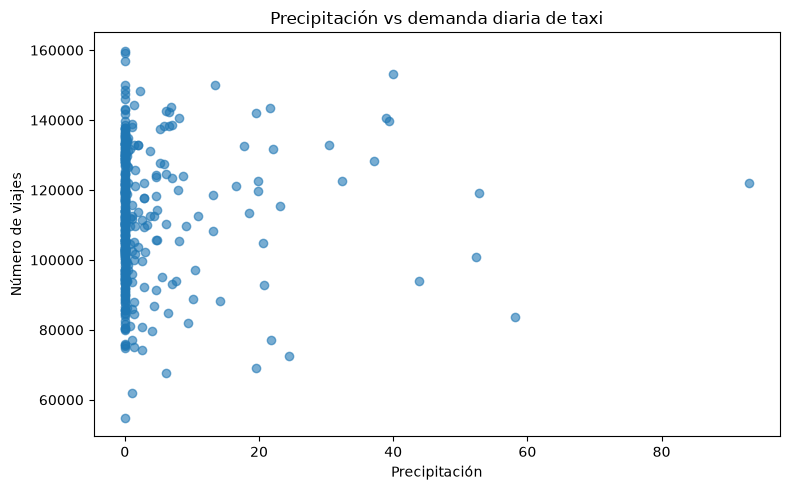

In [125]:
plt.figure(figsize=(8, 5))

plt.scatter(
    taxi_weather_pd["PRCP"],
    taxi_weather_pd["trips"],
    alpha=0.6
)

plt.title("Precipitación vs demanda diaria de taxi")
plt.xlabel("Precipitación")
plt.ylabel("Número de viajes")

plt.tight_layout()
plt.show()

**Lectura de la figura.** Muchos días se concentran cerca de precipitación cero, pero sus volúmenes de viajes son muy diferentes. En días lluviosos también se observa dispersión considerable, coherente con la baja correlación lineal de `PRCP` (+0.0457). **No se aprecia una relación lineal fuerte** a esta resolución temporal.

### 6.3. Análisis adicional — días con y sin precipitación

Se divide el año en días con `PRCP > 0` y `PRCP = 0`, y se comparan el número de días, la **media** y la **mediana** de viajes. El cálculo se hace sobre las 366 filas de la tabla diaria en pandas.

La categoría «con precipitación» agrupa todas las intensidades positivas; no distingue llovizna de lluvia intensa ni controla el día de semana o la temporada. Por tanto, esta comparación sigue siendo descriptiva.

       rain_group  dias  media_viajes  mediana_viajes
Con precipitación   125 112270.528000        112652.0
Sin precipitación   241 112596.879668        111714.0


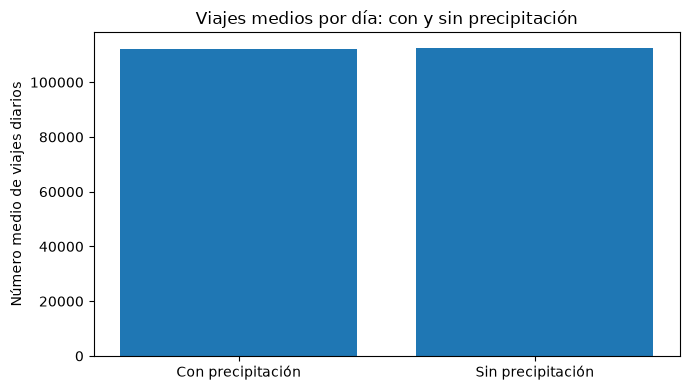

In [126]:
weather_comparison_pd = taxi_weather_pd.copy()
weather_comparison_pd["pickup_date"] = pd.to_datetime(weather_comparison_pd["pickup_date"])
weather_comparison_pd["rain_group"] = weather_comparison_pd["PRCP"].apply(
    lambda value: "Con precipitación" if value > 0 else "Sin precipitación"
)

rain_summary_pd = (
    weather_comparison_pd.groupby("rain_group")
    .agg(dias=("trips", "size"), media_viajes=("trips", "mean"),
         mediana_viajes=("trips", "median"))
    .reset_index()
)
print(rain_summary_pd.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(rain_summary_pd["rain_group"], rain_summary_pd["media_viajes"])
plt.title("Viajes medios por día: con y sin precipitación")
plt.ylabel("Número medio de viajes diarios")
plt.tight_layout()
plt.show()

**Interpretación — días con/sin precipitación.** Se observaron **125 días con precipitación** y **241 sin ella**. Sus medias de viajes fueron **112,270.53** y **112,596.88**, respectivamente: una diferencia de **−326.35 viajes diarios**, equivalente a solo **−0.29 %** respecto a los días sin precipitación.

Las **medianas** muestran incluso el signo inverso (**112,652** con precipitación frente a **111,714** sin ella). Ambas comparaciones indican que, con este corte binario, **no aparece una separación grande y consistente en la demanda**. Esto no descarta efectos por intensidad de lluvia, hora, temporada o zona; además, no se han controlado otros factores del calendario.

### 6.4. Análisis adicional — desviación respecto al patrón semanal

Para explorar si la asociación entre precipitación y viajes puede estar confundida por la actividad típica de cada día, calculamos:

$$
	ext{desviación}_d = 	ext{viajes}_d - \overline{	ext{viajes}}_{	ext{día de semana}(d)}.
$$

A continuación se calcula la correlación de `PRCP` con esa **desviación de demanda** y se visualizan los puntos. El procedimiento descuenta de la respuesta el promedio por día de semana, pero **no equivale a una correlación parcial** ni elimina estacionalidad, festivos, eventos u oferta disponible. No se usa para inferir efectos causales.

Correlación PRCP vs desviación del promedio semanal: 0.0065


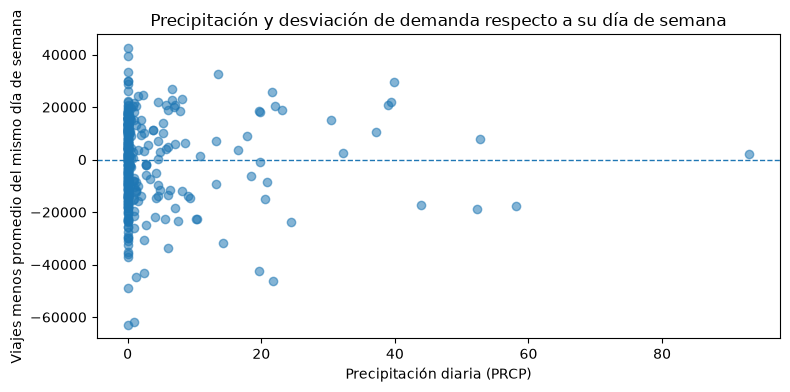

In [127]:
weather_comparison_pd["weekday"] = weather_comparison_pd["pickup_date"].dt.dayofweek
weather_comparison_pd["weekday_mean_trips"] = (
    weather_comparison_pd.groupby("weekday")["trips"].transform("mean")
)
weather_comparison_pd["weekday_deviation"] = (
    weather_comparison_pd["trips"] - weather_comparison_pd["weekday_mean_trips"]
)

adjusted_r = weather_comparison_pd["PRCP"].corr(
    weather_comparison_pd["weekday_deviation"]
)
print(f"Correlación PRCP vs desviación del promedio semanal: {adjusted_r:.4f}")

plt.figure(figsize=(8, 4))
plt.scatter(weather_comparison_pd["PRCP"],
            weather_comparison_pd["weekday_deviation"], alpha=0.55)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Precipitación y desviación de demanda respecto a su día de semana")
plt.xlabel("Precipitación diaria (PRCP)")
plt.ylabel("Viajes menos promedio del mismo día de semana")
plt.tight_layout()
plt.show()

**Interpretación — precipitación tras descontar el promedio semanal.** La correlación entre `PRCP` y la desviación de viajes respecto a su día de semana es **+0.0065**, frente a **+0.0457** para `PRCP` y viajes diarios sin ese ajuste descriptivo. En ambos casos la relación lineal observada es **prácticamente nula**.

El diagrama exhibe una dispersión amplia de desviaciones para valores similares de precipitación, especialmente cerca de `PRCP = 0`. El resultado **no implica que la lluvia no tenga efecto**: solo muestra que esta variable, por sí sola y a resolución diaria, no se asocia linealmente de forma apreciable con la desviación empleada. No se han controlado simultáneamente la precipitación por día de semana, la estacionalidad ni eventos externos.

## 7. Indicadores de cierre y consideraciones

Como recapitulación se calculan el número total de pickups incluidos, los días observados, las medias brutas de algunas variables y la cardinalidad de zonas.

**Importante:** al no aplicar una limpieza completa, las medias brutas de distancia, duración e importe **pueden verse afectadas por valores extremos**, identificados en `03_03`. Para describir viajes típicos son más informativos los cuantiles del apartado 3.

In [128]:
exploration_summary_df = (
    taxi_2024_df
    .agg(
        F.count("*").alias("trips"),

        F.countDistinct(
            "pickup_date"
        ).alias("days"),

        F.avg(
            "trip_distance"
        ).alias("avg_distance"),

        F.avg(
            "duration_minutes"
        ).alias("avg_duration"),

        F.avg(
            "total_amount"
        ).alias("avg_total_amount"),

        F.countDistinct(
            "PULocationID"
        ).alias("pickup_zones"),

        F.countDistinct(
            "DOLocationID"
        ).alias("dropoff_zones")
    )
)

exploration_summary_df.show(
    truncate=False
)

+--------+----+-----------------+------------------+------------------+------------+-------------+
|trips   |days|avg_distance     |avg_duration      |avg_total_amount  |pickup_zones|dropoff_zones|
+--------+----+-----------------+------------------+------------------+------------+-------------+
|41169664|366 |4.976098943629698|17.467351031009613|27.832795809511673|263         |262          |
+--------+----+-----------------+------------------+------------------+------------+-------------+



**Resultado.** La vista analítica contiene **41,169,664 viajes** y cubre **366 días**. Las medias calculadas sobre el conjunto sin depuración definitiva son aproximadamente **4.98** unidades de distancia, **17.47 minutos** de duración y **27.83** unidades monetarias de importe total. Hay **263 ID distintos de origen** y **262 de destino**.

Las cifras no deben interpretarse como estadísticas definitivas de viajes válidos hasta implementar y justificar formalmente los filtros del pipeline. Tampoco debe confundirse el número de ID observados con el catálogo completo de zonas de NYC.

## 8. Conclusiones y transición a la siguiente fase

### 8.1. Hallazgos observados

| Dimensión | Resultado sustentado por las salidas |
|---|---|
| **Volumen** | Se analizaron **41,169,664 pickups** fechados en 2024, distribuidos entre **366 días**. |
| **Variación mensual** | Octubre registró **3,833,780 viajes** y lideró también en promedio diario (**123,670**), frente a **95,633 diarios** en enero: diferencia aproximada de **29.3 %**. |
| **Variación diaria** | El día de menor demanda fue **2024-12-25 (54,764)** y el de mayor **2024-12-13 (159,845)**. La media móvil de siete días muestra fluctuaciones que los totales mensuales ocultan. |
| **Patrón semanal** | Un jueves típico registró **123,618 viajes**, frente a **96,485 los lunes** (≈ **28.1 %** más). La madrugada es menos activa que la tarde y el máximo horario se sitúa alrededor de las **18:00**. |
| **Características de viaje** | Distancia: **P50 = 1.76**, **P99 = 19.95**; duración: **P50 = 13.00 min**, **P99 = 70.20 min**; importe: **P50 = 21.00**, **P99 = 104.88**. Las distribuciones presentan colas derechas. |
| **Concentración por zonas** | Los mayores volúmenes se concentran en un conjunto reducido de `PULocationID` y `DOLocationID`; todavía no se han enriquecido con el catálogo geográfico. |
| **Integración con NOAA** | La unión diaria conserva **366 fechas**, con **cuatro faltantes de `AWND`** y cobertura completa en las demás variables seleccionadas. |
| **Precipitación y demanda** | En **125 días con precipitación** hubo una media de **112,271 viajes**, frente a **112,597** en **241 días secos**: diferencia de apenas **−0.29 %**. La correlación simple `PRCP`–viajes fue **+0.0457** y con la desviación frente al patrón semanal fue **+0.0065**. |

### 8.2. Interpretación y límites

- La demanda **varía de forma marcada por mes, día de semana y hora**; es recomendable conservar esas características temporales en los conjuntos analíticos posteriores. Los descensos en ciertas fechas coinciden con días festivos, pero no constituyen evidencia causal de un efecto del calendario.
- Las distribuciones de distancia, duración y montos poseen **valores extremos** previamente identificados en `03_03`. Los histogramas utilizan un **filtrado simultáneo al P99 más una muestra aleatoria** exclusivamente para visualizar; no representan toda la distribución original ni establecen una regla de eliminación.
- Las comparaciones climáticas muestran **asociaciones descriptivas débiles**, no ausencia demostrada de efecto. Agrupar días como lluviosos/secos puede ocultar relaciones no lineales; además, la información procede de **una sola estación** y tiene resolución diaria, mientras que los viajes ocurren en horas y zonas distintas.
- La correlación de **0.0065** corresponde a `PRCP` frente a la demanda con el promedio de su día de semana sustraído. **No es una estimación de efecto causal ni una correlación parcial controlada** por todas las variables temporales.
- La capa `raw` permanece intacta. El filtro de pickups en 2024 y las vistas temporales del notebook son **decisiones exploratorias**, independientes de la limpieza definitiva.

### 8.3. Implicaciones para la fase 04 — ETL y transformaciones

1. **Calidad de viajes:** establecer reglas trazables sobre fechas, duración, distancias e importes; tratar de forma diferenciada ajustes monetarios y el grupo estructural con `payment_type = 0`.
2. **Modelado temporal:** generar columnas de fecha, mes, día de semana y hora con definiciones uniformes, sin depender de los gráficos ni de decisiones implícitas del EDA.
3. **Enriquecimiento espacial:** integrar *Taxi Zone Lookup* para interpretar códigos de origen/destino y comprobar su validez.
4. **Enriquecimiento meteorológico:** construir un dataset diario consistente, preservar los **cuatro días sin `AWND`** y justificar cualquier imputación, si se decide realizarla.
5. **Controles reproducibles:** validar número de registros, unicidad de claves, integridad de las uniones y diferencias entre los datos de origen y los transformados.

**Cierre de la fase 03:** las fuentes Taxi y NOAA ya fueron ingeridas, perfiladas y exploradas. Las decisiones de limpieza e integración de la fase siguiente pueden justificarse con observaciones verificables, sin haber sobrescrito los datos de origen.